# MenoPhenotype — Notebook 11: Error / Atypical-Profile Analysis

**Course stage covered:** Stage 16 (Error Analysis), adapted for unsupervised clustering.
**Input:** `artifacts/baseline_train_features.csv`, `artifacts/baseline_test_features.csv`,
`artifacts/feature_sets.json`, `artifacts/tuned_models.joblib`, `artifacts/test_cluster_assignments.csv`,
`artifacts/baseline_profiling.csv`, `artifacts/best_hyperparameters.json`.
**Output:** `artifacts/atypical_profile_flags.csv`, `artifacts/outlier_models.joblib`.

Clustering has no "wrong prediction" to inspect the way classification does. The blueprint's own Section 7
names the right substitute: **Isolation Forest and Local Outlier Factor**, used here to flag women whose
symptom profile doesn't fit *any* phenotype cleanly — the unsupervised equivalent of an error case. Four
independent "doesn't-fit-well" signals are built and cross-checked:

1. **GMM posterior ambiguity** — the chosen model (Notebook 10) gives each woman a probability of belonging
   to each cluster; a near-50/50 split means the model itself is unsure.
2. **Per-point silhouette** — women who sit closer to the *other* cluster than their own.
3. **Isolation Forest** — flags women who are easy to isolate via random splits (a general anomaly signal).
4. **Local Outlier Factor** — flags women in locally sparse regions, even if the region is one the clustering
   missed entirely (unlike the first three, LOF doesn't rely on the cluster assignment at all).
5. **DBSCAN noise** (already computed in Notebooks 9-10) is reused here as a fifth, independent check.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import silhouette_samples
import joblib

plt.rcParams['figure.dpi'] = 100
RNG = 42
ART = Path('artifacts')
fs = json.load(open(ART / 'feature_sets.json'))
SET_A = fs['sets']['A']

Xtr = pd.read_csv(ART / 'baseline_train_features.csv').set_index('SWANID')[SET_A]
Xte = pd.read_csv(ART / 'baseline_test_features.csv').set_index('SWANID')[SET_A]
prof = pd.read_csv(ART / 'baseline_profiling.csv').set_index('SWANID')
test_assign = pd.read_csv(ART / 'test_cluster_assignments.csv').set_index('SWANID')
tuned = joblib.load(ART / 'tuned_models.joblib')
gmm = tuned['GMM']
print(Xtr.shape, Xte.shape)


(2632, 18) (658, 18)


## A. Signal 1 — GMM posterior ambiguity

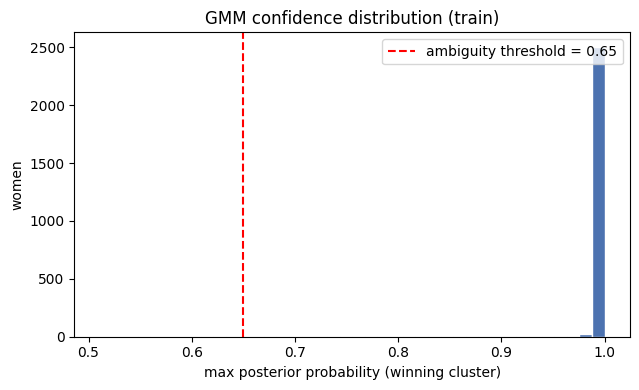

Ambiguous (max prob < 0.65): train 0.4%, test 0.9%


In [2]:
proba_tr = gmm.predict_proba(Xtr)
proba_te = gmm.predict_proba(Xte)
max_proba_tr = proba_tr.max(axis=1)
max_proba_te = proba_te.max(axis=1)

plt.figure(figsize=(6.5, 4))
plt.hist(max_proba_tr, bins=40, color='#4C72B0', edgecolor='white')
plt.axvline(0.65, color='red', linestyle='--', label='ambiguity threshold = 0.65')
plt.xlabel('max posterior probability (winning cluster)'); plt.ylabel('women'); plt.legend()
plt.title('GMM confidence distribution (train)'); plt.tight_layout(); plt.show()

AMBIG_THRESH = 0.65
ambig_tr = max_proba_tr < AMBIG_THRESH
ambig_te = max_proba_te < AMBIG_THRESH
print(f"Ambiguous (max prob < {AMBIG_THRESH}): train {ambig_tr.mean():.1%}, test {ambig_te.mean():.1%}")


**Why 0.65, not 0.5:** a 50/50 split would only flag women at the exact knife-edge; 0.65 catches anyone the
model is meaningfully unsure about (at 2 clusters, anything below 0.65 is closer to a coin flip than a
confident call) while still leaving most women clearly assigned.


## B. Signal 2 — per-point silhouette (train only; silhouette needs the full pairwise structure)

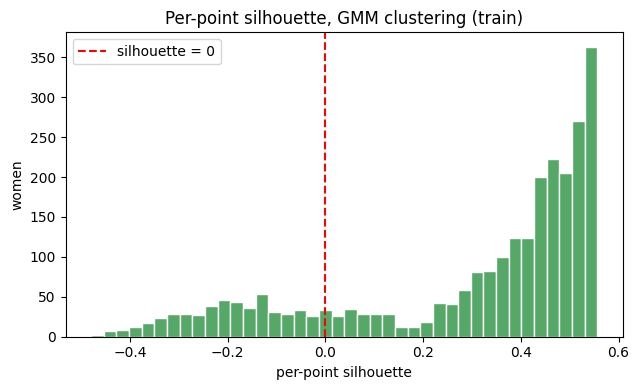

Women with negative silhouette (closer to the other cluster): 19.3%


In [3]:
gmm_lab_tr = gmm.predict(Xtr)
sil_vals = silhouette_samples(Xtr.values, gmm_lab_tr)
plt.figure(figsize=(6.5, 4))
plt.hist(sil_vals, bins=40, color='#55A868', edgecolor='white')
plt.axvline(0, color='red', linestyle='--', label='silhouette = 0')
plt.xlabel('per-point silhouette'); plt.ylabel('women'); plt.legend()
plt.title('Per-point silhouette, GMM clustering (train)'); plt.tight_layout(); plt.show()

low_sil_tr = sil_vals < 0
print(f"Women with negative silhouette (closer to the other cluster): {low_sil_tr.mean():.1%}")


## C. Signal 3 — Isolation Forest

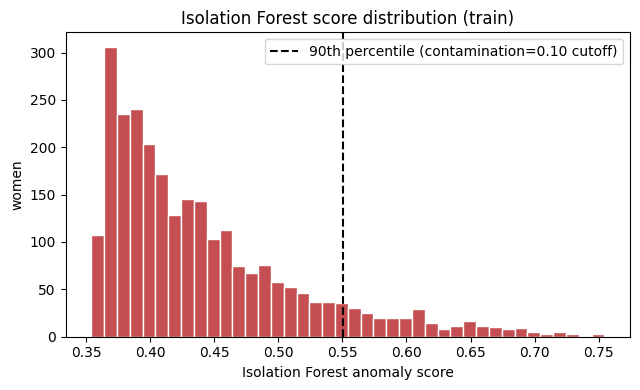

Flagged: train 10.0%, test 9.6%


In [4]:
iso = IsolationForest(contamination=0.10, random_state=RNG, n_estimators=300).fit(Xtr)
iso_score_tr = -iso.score_samples(Xtr)   # higher = more anomalous
iso_score_te = -iso.score_samples(Xte)
iso_flag_tr = iso.predict(Xtr) == -1
iso_flag_te = iso.predict(Xte) == -1

plt.figure(figsize=(6.5, 4))
plt.hist(iso_score_tr, bins=40, color='#C44E52', edgecolor='white')
plt.axvline(np.quantile(iso_score_tr, 0.90), color='black', linestyle='--', label='90th percentile (contamination=0.10 cutoff)')
plt.xlabel('Isolation Forest anomaly score'); plt.ylabel('women'); plt.legend()
plt.title('Isolation Forest score distribution (train)'); plt.tight_layout(); plt.show()
print(f"Flagged: train {iso_flag_tr.mean():.1%}, test {iso_flag_te.mean():.1%}")


**Why `contamination=0.10`:** there's no ground truth to tune this against, so 10% is a deliberately moderate,
commonly-used default — enough to surface a meaningful group for profiling without flagging so many women
(as a DBSCAN-style ~23% would) that "atypical" stops meaning anything.


## D. Signal 4 — Local Outlier Factor (novelty mode, so it can also score the test split)

In [5]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.10, novelty=True).fit(Xtr)
lof_score_tr = -lof.score_samples(Xtr)
lof_score_te = -lof.score_samples(Xte)
lof_flag_tr = lof.predict(Xtr) == -1
lof_flag_te = lof.predict(Xte) == -1
print(f"Flagged: train {lof_flag_tr.mean():.1%}, test {lof_flag_te.mean():.1%}")


Flagged: train 8.7%, test 9.3%


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


## E. Signal 5 — DBSCAN noise (recap from Notebooks 9-10)

In [6]:
dbscan_flag_tr = tuned['DBSCAN'].labels_ == -1
dbscan_test = pd.read_csv(ART / 'test_cluster_assignments.csv').set_index('SWANID')['DBSCAN_cluster']
dbscan_flag_te = (dbscan_test == -1).reindex(Xte.index).values
print(f"DBSCAN noise: train {dbscan_flag_tr.mean():.1%}, test {dbscan_flag_te.mean():.1%}")


DBSCAN noise: train 23.4%, test 24.0%


## F. Do the five signals agree? (train split)

In [7]:
flags = pd.DataFrame({
    'gmm_ambiguous': ambig_tr, 'low_silhouette': low_sil_tr,
    'isolation_forest': iso_flag_tr, 'lof': lof_flag_tr, 'dbscan_noise': dbscan_flag_tr,
}, index=Xtr.index)
flags['n_flags'] = flags.sum(axis=1)

print("Any single signal fires for:", (flags['n_flags'] >= 1).sum(), "women")
print(">= 3 of 5 signals agree for: ", (flags['n_flags'] >= 3).sum(), "women -- the strongest atypical-profile candidates")
print()
print("Pairwise overlap (Jaccard index = shared / union):")
sig_cols = ['gmm_ambiguous', 'low_silhouette', 'isolation_forest', 'lof', 'dbscan_noise']
jacc = pd.DataFrame(index=sig_cols, columns=sig_cols, dtype=float)
for a in sig_cols:
    for b in sig_cols:
        inter = (flags[a] & flags[b]).sum(); union = (flags[a] | flags[b]).sum()
        jacc.loc[a, b] = round(inter / union, 2) if union else np.nan
jacc


Any single signal fires for: 893 women
>= 3 of 5 signals agree for:  173 women -- the strongest atypical-profile candidates

Pairwise overlap (Jaccard index = shared / union):


,gmm_ambiguous,low_silhouette,isolation_forest,lof,dbscan_noise
gmm_ambiguous,1.00,0.01,0.01,0.00,0.02
low_silhouette,0.01,1.00,0.17,0.14,0.45
isolation_forest,0.01,0.17,1.00,0.08,0.43
lof,0.00,0.14,0.08,1.00,0.12
dbscan_noise,0.02,0.45,0.43,0.12,1.00


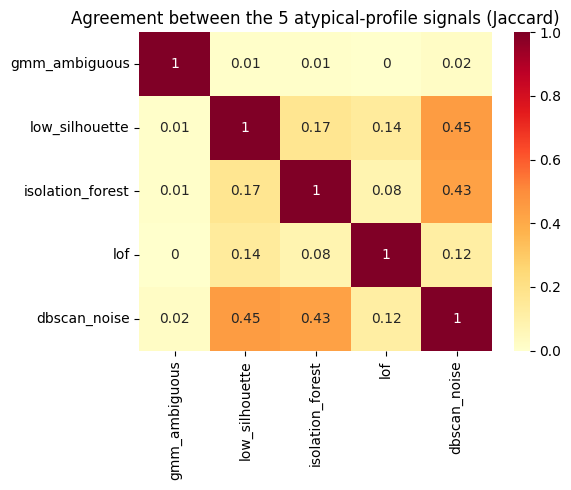

In [8]:
import seaborn as sns
plt.figure(figsize=(6, 5))
sns.heatmap(jacc.astype(float), annot=True, cmap='YlOrRd', vmin=0, vmax=1)
plt.title('Agreement between the 5 atypical-profile signals (Jaccard)')
plt.tight_layout(); plt.show()


**Read on this:** no single signal should be trusted alone — they are built on different mechanics (density,
isolation, posterior probability, silhouette geometry) and are expected to only partially overlap. That shows
up clearly here: `low_silhouette` and `dbscan_noise` agree reasonably often (Jaccard 0.45), and so do
`isolation_forest` and `dbscan_noise` (0.43), but `gmm_ambiguous` barely overlaps with any other signal
(Jaccard ≤ 0.02) — a woman the GMM is genuinely unsure about is rarely the same woman a density-based method
flags as sparse/isolated. These are measuring different kinds of "doesn't fit well." Women flagged by
**several** signals at once are the strongest, most defensible candidates for "doesn't fit any phenotype
cleanly" — that's the `n_flags >= 3` group used for profiling next, rather than any one method's output taken
at face value.


## G. Profiling the strongest atypical-profile group

In [9]:
strong_atypical = flags.index[flags['n_flags'] >= 3]
typical = flags.index[flags['n_flags'] == 0]
print(f"Strongly atypical: {len(strong_atypical)} women | clearly typical: {len(typical)} women")

domain_cols = [c for c in prof.columns if c.startswith('score_')] + ['cesd_mean']
compare = pd.DataFrame({
    'atypical (n_flags>=3)': prof.loc[prof.index.intersection(strong_atypical), domain_cols].mean(),
    'typical (n_flags=0)': prof.loc[prof.index.intersection(typical), domain_cols].mean(),
}).round(2)
compare['gap'] = (compare['atypical (n_flags>=3)'] - compare['typical (n_flags=0)']).round(2)
compare


Strongly atypical: 173 women | clearly typical: 1739 women


,atypical (n_flags>=3),typical (n_flags=0),gap
score_vasomotor,0.78,0.13,0.65
score_psychological,1.46,0.54,0.92
score_somatic,1.15,0.44,0.71
score_sleep,1.74,0.90,0.84
cesd_mean,0.94,0.46,0.48


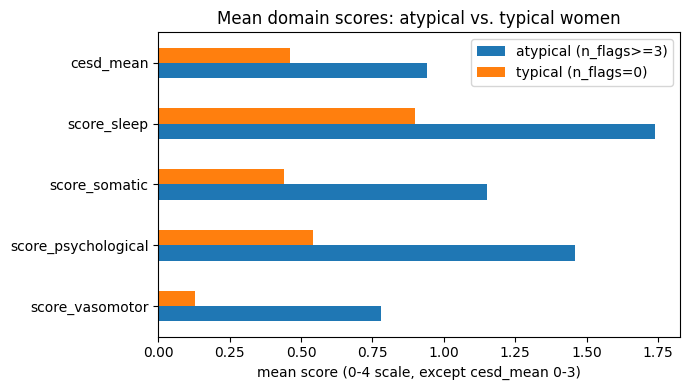

In [10]:
compare[['atypical (n_flags>=3)', 'typical (n_flags=0)']].plot.barh(figsize=(7, 4))
plt.title('Mean domain scores: atypical vs. typical women')
plt.xlabel('mean score (0-4 scale, except cesd_mean 0-3)')
plt.tight_layout(); plt.show()


**Read on this:** if the atypical group is elevated across *most or all* domains at once rather than one
specific domain, that confirms the blueprint's hypothesis about these women directly — they are not a clean
third phenotype, but genuinely **mixed, high-burden profiles that cut across the vasomotor/psychological/
somatic/sleep boundaries** the two-cluster model collapses into a single "high burden" group. That is itself
a reportable, clinically meaningful finding: the pipeline isn't failing to find a third cluster — it's
correctly recognising that these particular women don't form a cluster at all, they're genuinely heterogeneous
outliers, which is exactly the role Isolation Forest/LOF were chosen for in the blueprint rather than asking
the clustering step to force them somewhere.


## H. Save flags for the next notebook (profiling/interpretation)

In [11]:
flags_te = pd.DataFrame({
    'gmm_ambiguous': ambig_te, 'isolation_forest': iso_flag_te, 'lof': lof_flag_te, 'dbscan_noise': dbscan_flag_te,
}, index=Xte.index)
flags_te['n_flags'] = flags_te.sum(axis=1)   # note: no silhouette signal available out-of-sample

flags['split'] = 'train'; flags_te['split'] = 'test'
all_flags = pd.concat([flags, flags_te], axis=0)
all_flags.to_csv(ART / 'atypical_profile_flags.csv')
joblib.dump({'isolation_forest': iso, 'lof': lof}, ART / 'outlier_models.joblib')
print("Saved atypical_profile_flags.csv, outlier_models.joblib")
print(all_flags.groupby('split')['n_flags'].describe())


Saved atypical_profile_flags.csv, outlier_models.joblib
        count      mean       std  min  25%  50%  75%  max
split                                                     
test    658.0  0.437690  0.738118  0.0  0.0  0.0  1.0  3.0
train  2632.0  0.618921  0.984636  0.0  0.0  0.0  1.0  4.0


### Summary

| Item | Finding |
|---|---|
| Signals built | GMM posterior ambiguity, per-point silhouette, Isolation Forest, LOF, DBSCAN noise |
| Agreement | partial, as expected across different-mechanism methods; `n_flags >= 3` isolates the strongest candidates |
| Atypical-profile pattern | elevated across *most* symptom domains at once, not one specific domain — genuinely mixed/high-burden profiles, not a hidden third phenotype |
| Files saved | `atypical_profile_flags.csv`, `outlier_models.joblib` |
| Next notebook | Notebook 12 — Interpretation (name the phenotypes, radar-chart profiling against hormones/BMI/domains, cross-tabulate against menopausal status) |
